# STUDD — Full Scope Reproduction & Experimental Analysis Notebook

**Dự án:** Tái hiện toàn diện bài báo *"STUDD: A Student–Teacher Method for Unsupervised Concept Drift Detection"* (Cerqueira et al., *Machine Learning*, 2023) trên **toàn bộ 19 bộ dữ liệu × 10 phương pháp**.

**Quy chuẩn hạt giống (Seed Policy) trong phiên Full Scope:**
- **Teacher (`SEED_TEACHER`):** `42`
- **Student (`SEED_STUDENT`):** `142` *(tách khỏi Teacher để phá vỡ trùng khớp ngẫu nhiên trên mô hình stochastic như `RF/RF`)*
- **RNG mặt nạ & Monte Carlo (`SEED_RNG`):** `42`

**Mục lục:**
1. Programmatic 19-Dataset Loader & Cơ chế Fallback 3 tầng cho `Arabic` / `ArabicShuffled`
2. Kiểm chứng Quy trình Chọn Thuật toán 70/30 (Mục 5.6.2 & Bảng 2)
3. Tổng hợp 19 bộ (Bảng 3–4, Hình 10), Kiểm định Bayes độc lập (Hình 11–12) & Boxplot Labeling Efficiency Eq. (1)–(3) (Hình 13)
4. Phân tích Chất lượng Cảnh báo 19 bộ (Bảng 5) & Đồ thị Chuẩn hóa (Hình 7–8)
5. Phân tích Độ nhạy `l_access × l_delay` dạng 2×2 Average Rank trên 19 bộ (Mục 5.8.5, Hình 14, RQ3)
6. Đối chiếu Có Kiểm Soát Paper-Text (Protocol A) vs Author-Code (Protocol B) & Ablation Nguyên nhân Độ lệch


In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
import numpy as np

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

RESULTS_DIR = PROJECT_ROOT / "results"
runs_manifest = json.loads((RESULTS_DIR / "fullscope_wandb_runs.json").read_text(encoding="utf-8"))
print(f"Project root : {PROJECT_ROOT}")
print(f"W&B workspace: {runs_manifest['entity']}/{runs_manifest['project']}")
for k, v in runs_manifest["runs"].items():
    print(f" - {k:22s}: {v['url']}")


Project root : D:\hcmus\HK5\ML\GK\STUDD
W&B workspace: lgkai-hcmus/STUDD
 - table2_selection      : https://wandb.ai/lgkai-hcmus/STUDD/runs/5t33q8ec
 - bayesian_efficiency   : https://wandb.ai/lgkai-hcmus/STUDD/runs/5nfgcfv6
 - table5_alarms         : https://wandb.ai/lgkai-hcmus/STUDD/runs/he47zwzd
 - sensitivity_rq3       : https://wandb.ai/lgkai-hcmus/STUDD/runs/3qfje87x
 - protocol_ablation     : https://wandb.ai/lgkai-hcmus/STUDD/runs/yiouyosl


## 1. Bộ nạp 19 luồng dữ liệu & Fallback 3 tầng cho `Arabic` / `ArabicShuffled`


In [2]:
from src.data_loader import ALL_19_DATASETS, load_all_19_stream, _load_arabic_ts_fallback

rows_ds = []
for ds in ALL_19_DATASETS:
    X, y, meta = load_all_19_stream(ds)
    rows_ds.append({
        "Dataset": meta["canonical_name"],
        "Samples": meta["n_samples"],
        "Features": meta["n_features"],
        "Classes": meta["n_classes"],
        "W": meta["recommended_window_size"],
        "Source": str(meta["source"])[:55],
    })
df_19 = pd.DataFrame(rows_ds)
print(df_19.to_string(index=False))

X_fb, y_fb = _load_arabic_ts_fallback(str(PROJECT_ROOT / "data" / "dataset_huggingface" / "Arabic"), shuffled=True)
print(f"\n[Fallback Tier 3 Check] SpokenArabicDigits .ts -> shape={X_fb.shape}, classes={len(np.unique(y_fb))}")


       Dataset  Samples  Features  Classes    W                                                  Source
 InsectsAbrupt     5325        49        5  500                      cache:data\cache\AbruptInsects.zip
       Insects     5325        49        5  500  repo:data/dataset_not_huggingface/Insects/Insects.data
       Posture   150000         3       11 2000  repo:data/dataset_not_huggingface/Posture/Posture.data
        Arabic     8800        26       10 2000                 cache:data\cache\Arabic_Paper_Fixed.zip
          Bike    17379         4        2 2000            local:data\dataset_huggingface\Bike\Bike.csv
          NOAA    18159         8        2 2000         repo:data/dataset_not_huggingface/NOAA/NOAA.csv
       Sensors   150000         5       52 2000 repo:data/dataset_not_huggingface/Sensors/SensorStream.
   Powersupply    29928         2       24 2000 repo:data/dataset_not_huggingface/Powersupply/Powersupp
         Poker   150000        10        9 2000                 

## 2. Kiểm chứng Quy trình Chọn Thuật toán 70/30 (Mục 5.6.2, Bảng 2)


Teacher exact match vs Table 2: 7/19
Student exact match (given Our_T): 7/19
Student match (given Paper_T)   : 14/19
       Dataset    W Paper_Teacher Our_Best_Teacher  Paper_Teacher_Val_Kappa  Our_Best_Teacher_Val_Kappa Paper_Student Best_Student_Given_Paper_T
 InsectsAbrupt  500            RF               RC                   0.8225                      0.8737            RF                         RF
       Insects  500           XGB              SVC                   0.8320                      0.8985           XGB                        XGB
       Posture 2000           XGB              XGB                   0.5045                      0.5045            RF                        XGB
        Arabic 2000           XGB              SVC                   0.8980                      0.9425           XGB                        XGB
          Bike 2000           XGB               NB                   0.2101                      0.3397            RF                        XGB
          NOA

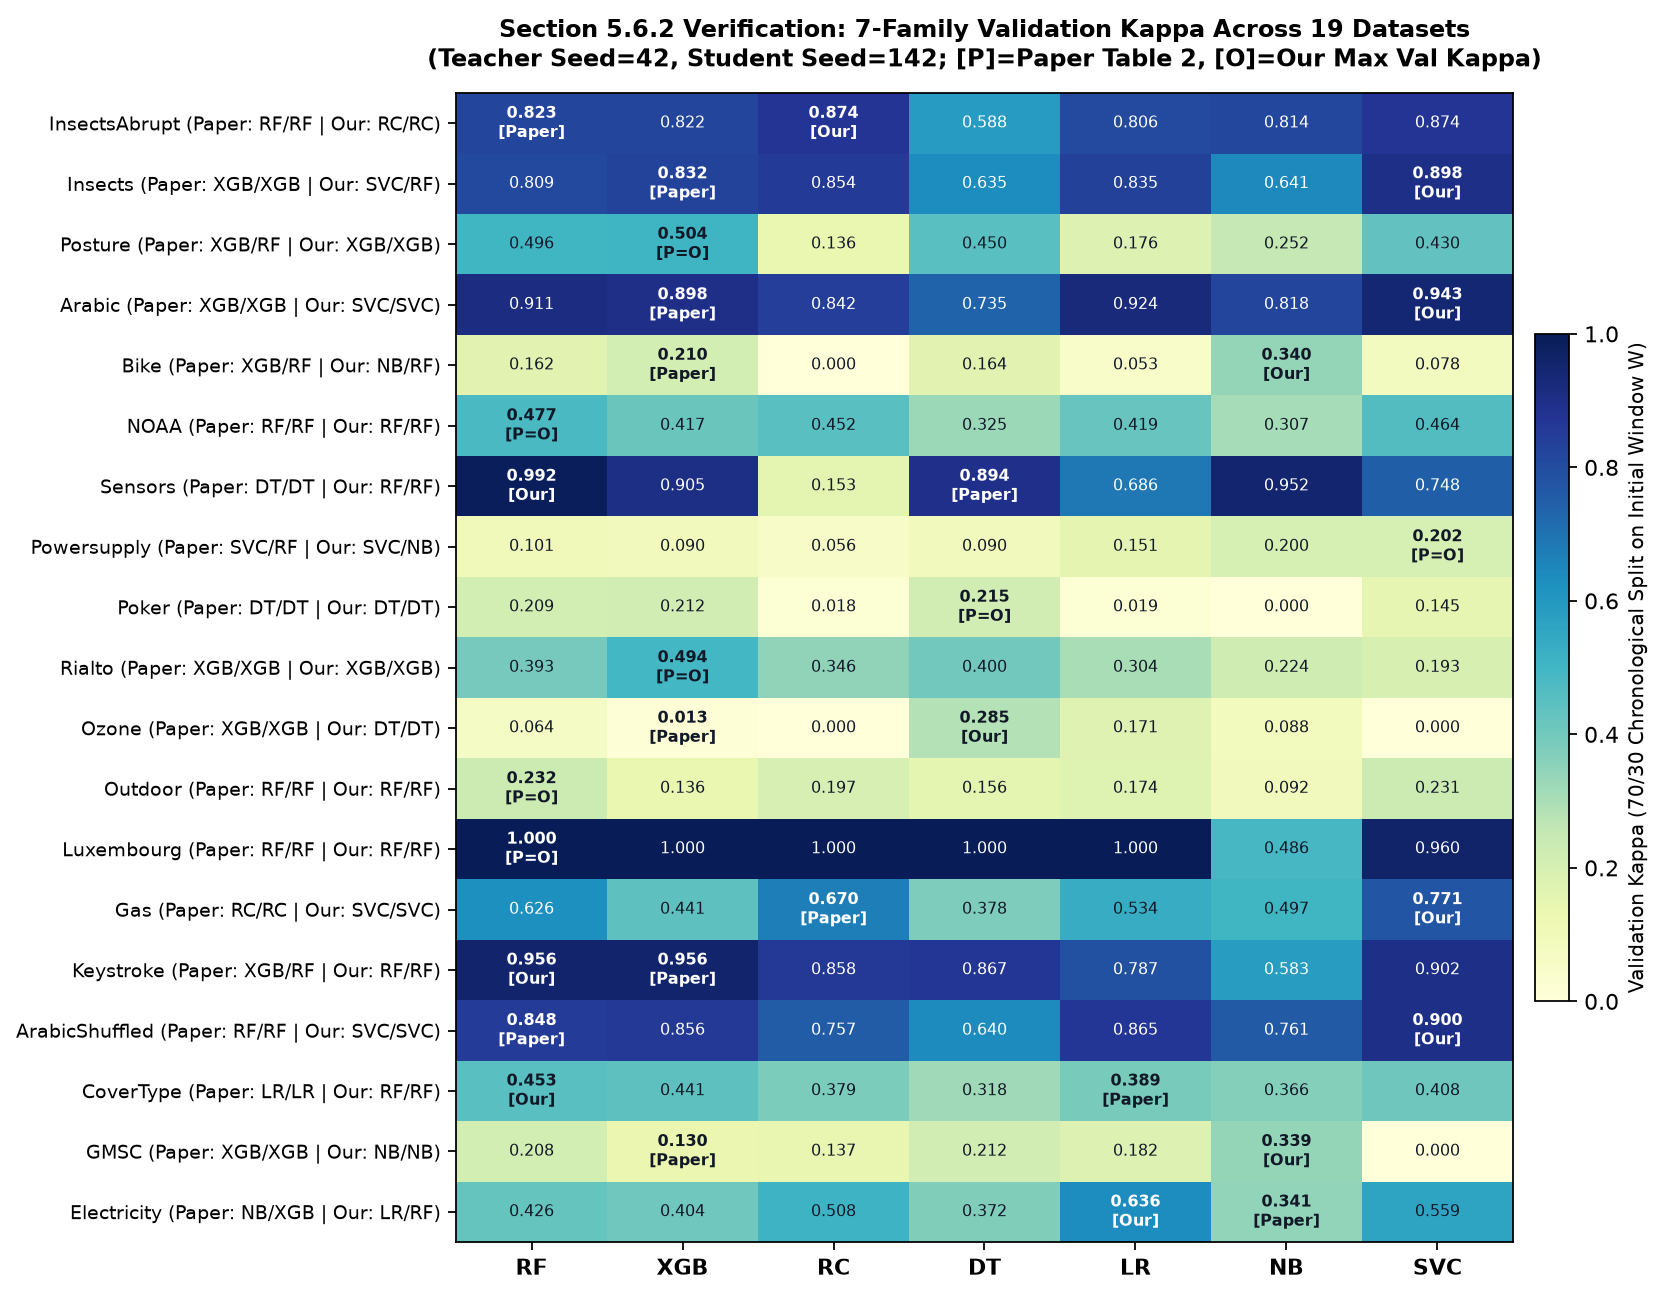

In [3]:
from experiments.verify_table2_selection import CANDIDATE_POOL

df_t2 = pd.read_csv(RESULTS_DIR / "table2_selection_verification.csv")
print(f"Teacher exact match vs Table 2: {int(df_t2['Teacher_Exact_Match'].sum())}/19")
print(f"Student exact match (given Our_T): {int(df_t2['Student_Exact_Match'].sum())}/19")
print(f"Student match (given Paper_T)   : {int(df_t2['Student_Match_Given_Paper_T'].sum())}/19")
print(df_t2[["Dataset", "W", "Paper_Teacher", "Our_Best_Teacher", "Paper_Teacher_Val_Kappa", "Our_Best_Teacher_Val_Kappa", "Paper_Student", "Best_Student_Given_Paper_T"]].to_string(index=False))
from IPython.display import Image as _IPyImg, display as _ipy_disp; _ipy_disp(_IPyImg(filename=str(RESULTS_DIR / "fig_table2_selection_heatmap.png")))


## 3. Tổng hợp 19 bộ (Bảng 3–4), Bayesian Sign Test độc lập (Hình 11–12) & Boxplot Labeling Efficiency (Hình 13)


=== LABELING EFFICIENCY (19 DATASETS — EQ. 1-3 + MEAN KAPPA/COST) ===
Method  Our_Mean_Kappa  Our_Mean_Cost  Our_Kappa_per_Cost  Our_Median_Eq1_3_Eff  Our_Mean_Eq1_3_Eff  Our_Pareto_Optimal
 STUDD          0.5002         0.2523              1.9821                1.0000              0.7171                True
 BL-st          0.4343         0.1150              3.7780                1.0000              1.0000                True
BL-ret          0.5553         0.9327              0.5954                0.1287              0.1896               False
    SS          0.5834         0.7952              0.7336                0.2829              0.4355                True
   DSS          0.5617         0.4904              1.1453                0.3191              0.4800                True
    WS          0.5752         0.5100              1.1277                0.6465              0.5817                True
   DWS          0.5508         0.3571              1.5423                0.6136           

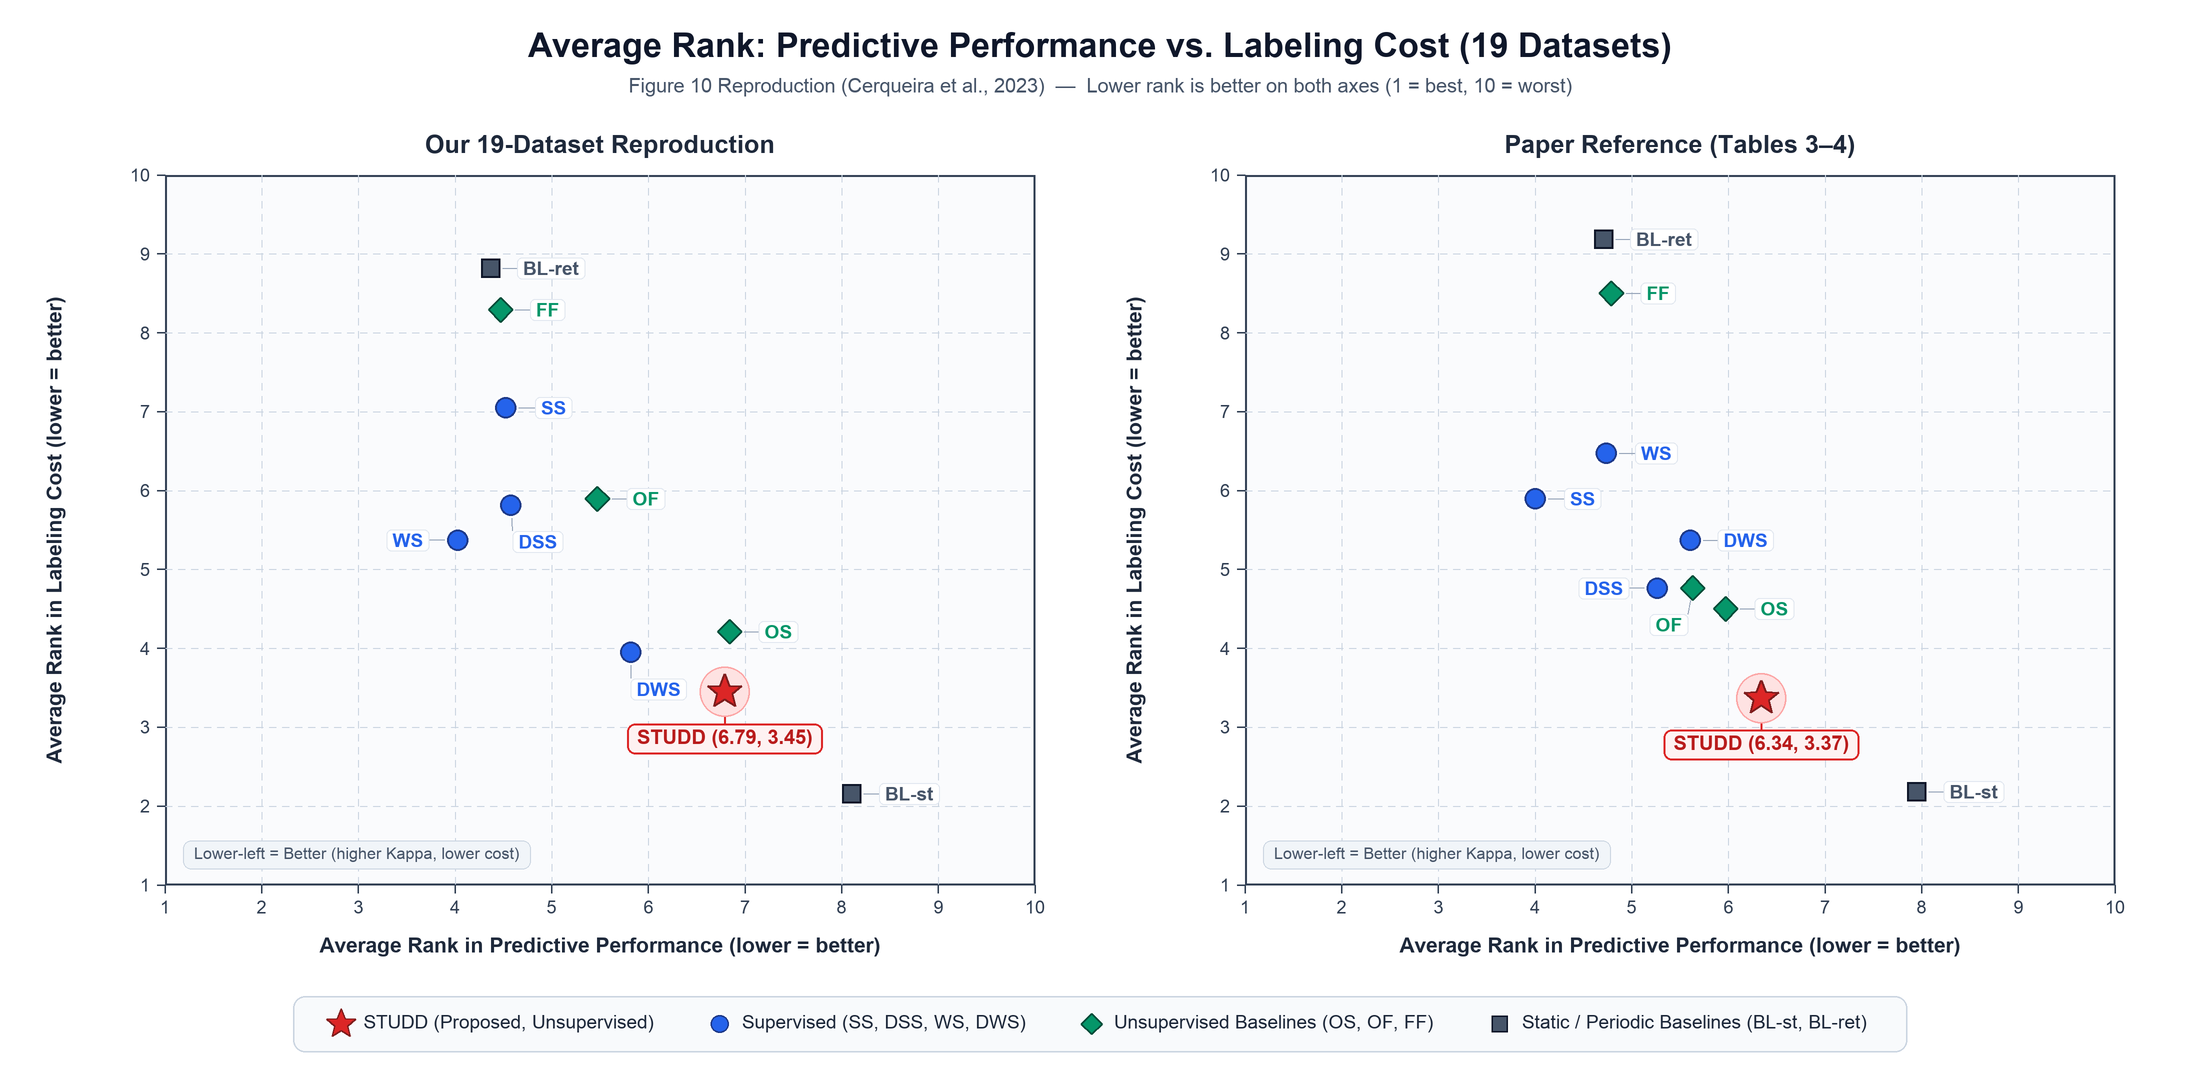

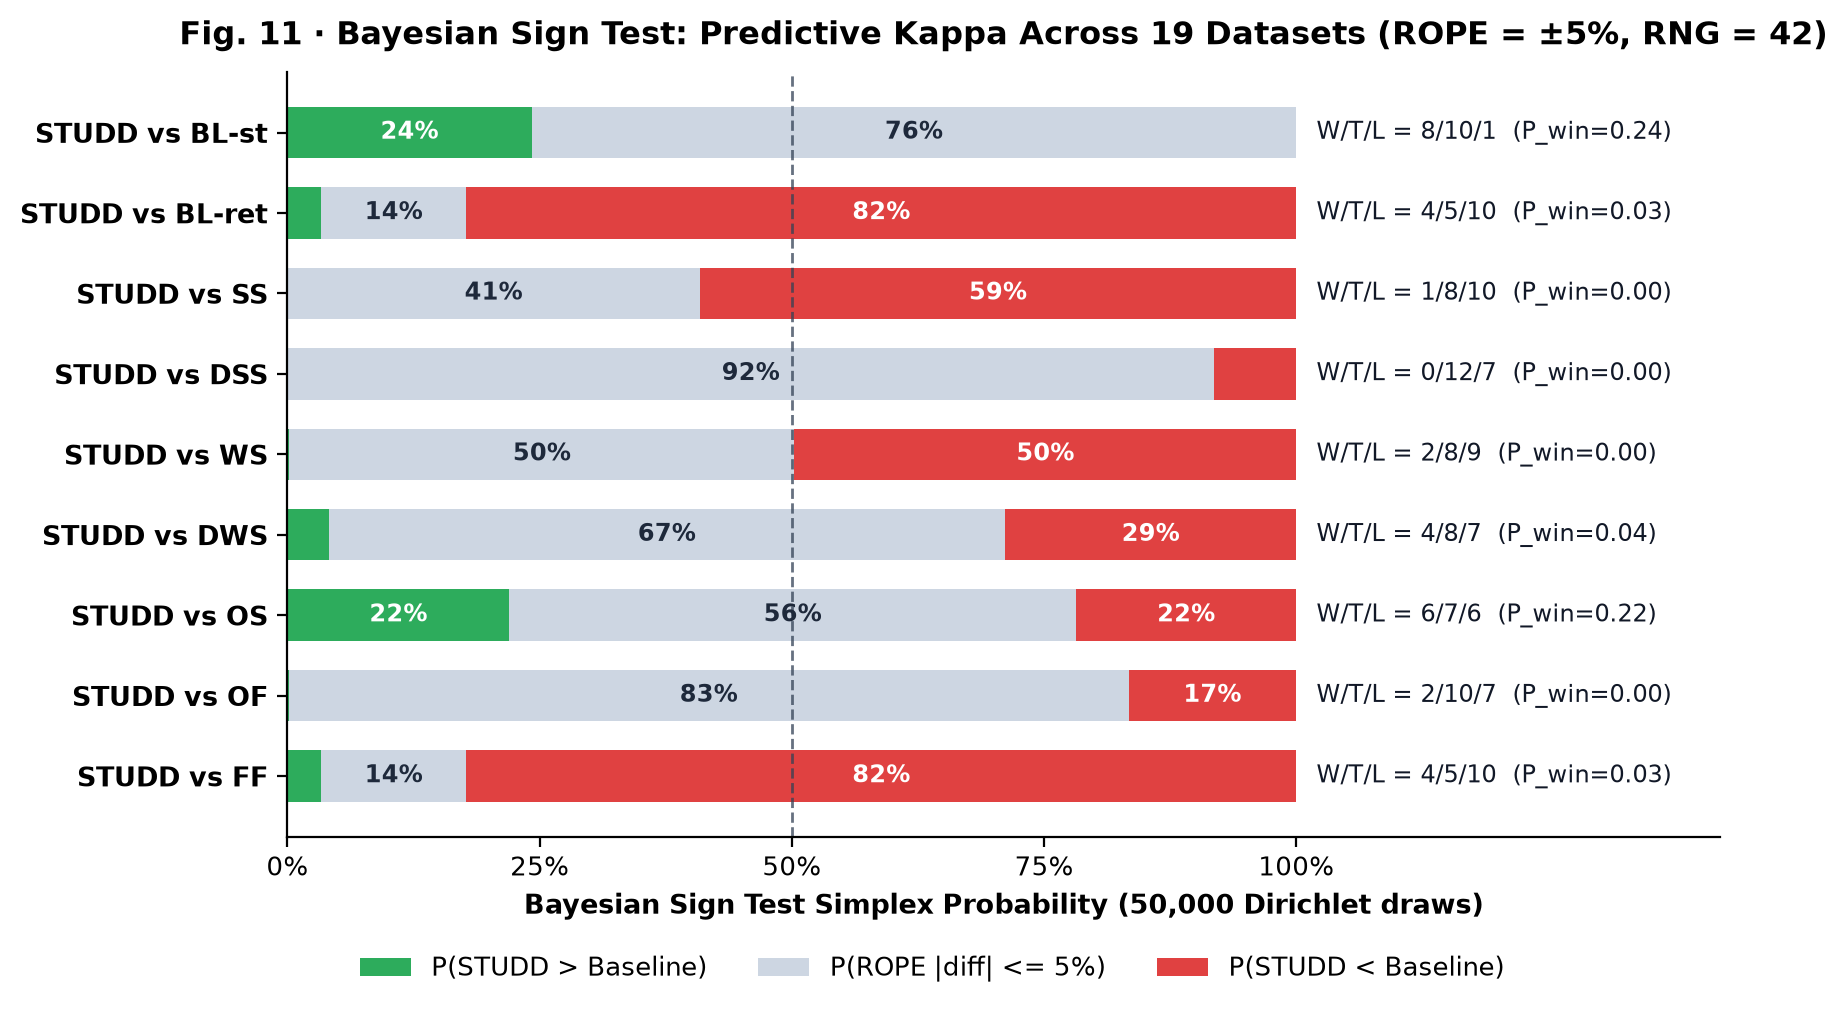

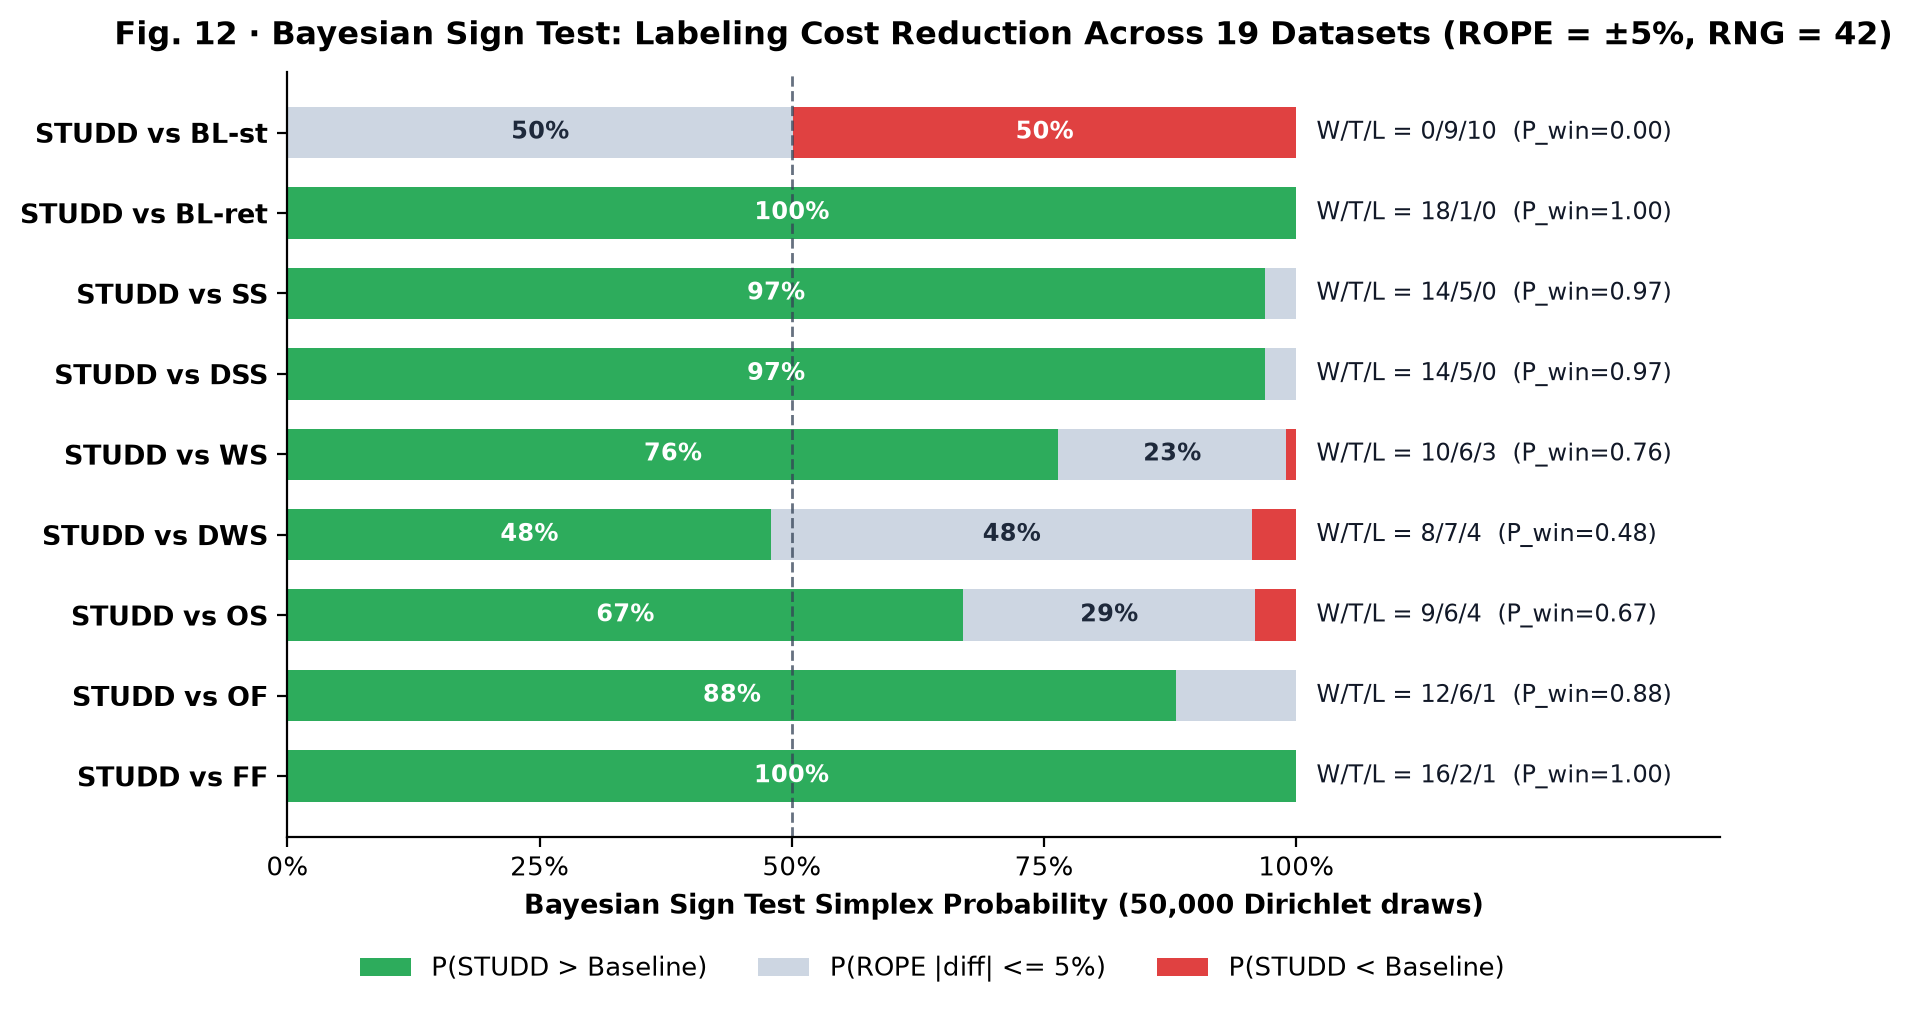

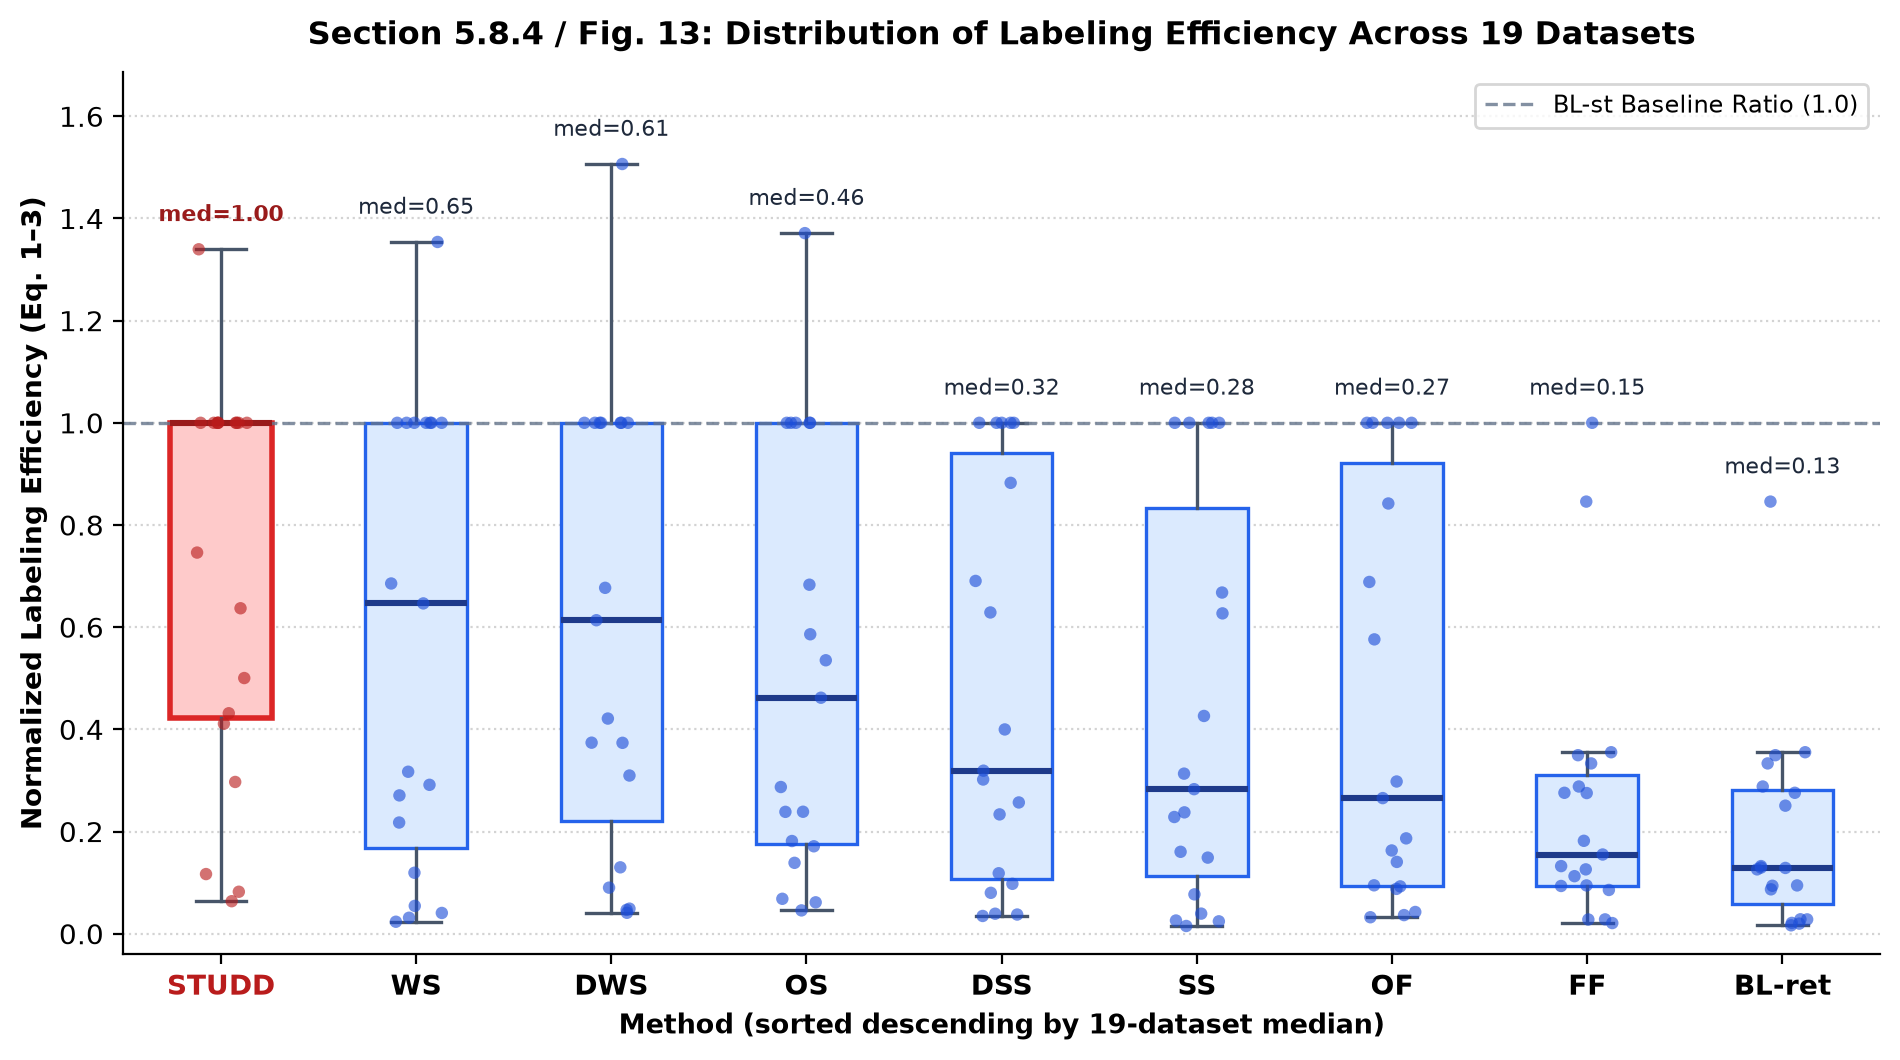

In [4]:
from experiments.analyze_19datasets_full import bayesian_sign_test_dirichlet

df_eff = pd.read_csv(RESULTS_DIR / "label_efficiency_19datasets.csv")
df_bayes = pd.read_csv(RESULTS_DIR / "bayesian_sign_test_summary.csv")

print("=== LABELING EFFICIENCY (19 DATASETS — EQ. 1-3 + MEAN KAPPA/COST) ===")
print(df_eff[["Method", "Our_Mean_Kappa", "Our_Mean_Cost", "Our_Kappa_per_Cost", "Our_Median_Eq1_3_Eff", "Our_Mean_Eq1_3_Eff", "Our_Pareto_Optimal"]].to_string(index=False))

print("\n=== BAYESIAN SIGN TEST (OUR REPRODUCTION, ROPE=+/-5%) ===")
sub_b = df_bayes[df_bayes["Source"] == "Our"]
print(sub_b[["Metric", "Baseline", "n_win", "n_rope", "n_lose", "Simplex_P_Win", "Simplex_P_ROPE", "Simplex_P_Lose"]].to_string(index=False))

from IPython.display import Image as _IPyImg, display as _ipy_disp; _ipy_disp(_IPyImg(filename=str(RESULTS_DIR / "fig_19datasets_rank_plot.png")))
from IPython.display import Image as _IPyImg, display as _ipy_disp; _ipy_disp(_IPyImg(filename=str(RESULTS_DIR / "fig11_bayesian_kappa.png")))
from IPython.display import Image as _IPyImg, display as _ipy_disp; _ipy_disp(_IPyImg(filename=str(RESULTS_DIR / "fig12_bayesian_cost.png")))
from IPython.display import Image as _IPyImg, display as _ipy_disp; _ipy_disp(_IPyImg(filename=str(RESULTS_DIR / "fig13_label_efficiency.png")))


## 4. Phân tích Cảnh báo Bảng 5 trên 19 bộ & Đồ thị Chuẩn hóa (Hình 7–8)


Method  SS_Alarmed_Datasets  Our_MDR  Paper_MDR  Our_FAR  Paper_FAR  Our_MTD  Paper_MTD  Total_Alarms_All19  F1_Windowed
 STUDD                   15   0.4000       0.19   0.0000       0.00   0.1535       0.09                 122       0.3174
   DSS                   15   0.0000       0.06   0.0000       0.00   0.1111       0.14                 292       0.6301
    WS                   15   0.1333       0.12   0.0000       0.00   0.1646       0.14                 337       0.6976
   DWS                   15   0.1333       0.19   0.0000       0.00   0.2032       0.16                 211       0.5073
    OS                   15   0.0667       0.06   0.0667       0.12   0.2153       0.12                 139       0.3212
    OF                   15   0.0667       0.06   0.2000       0.12   0.1184       0.11                 284       0.5373
    FF                   15   0.0000       0.00   0.2000       0.25   0.0938       0.07                 355       0.5743

Sanity check greedy alarm match

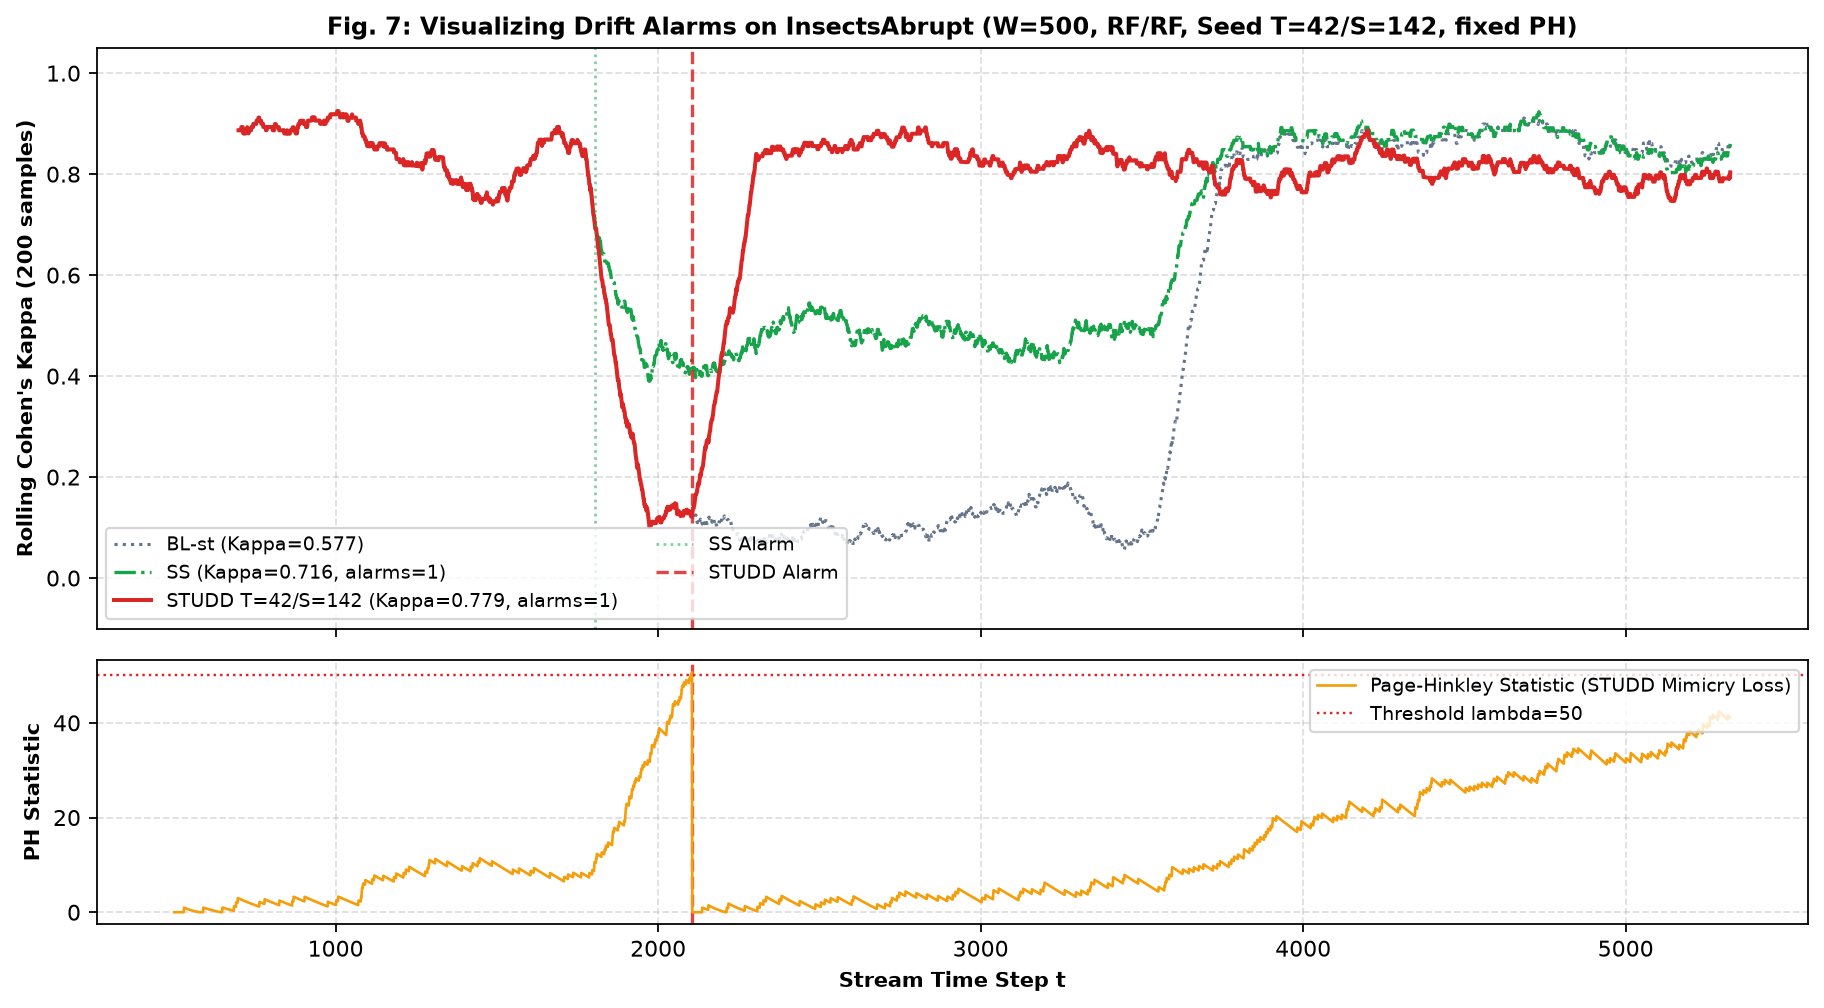

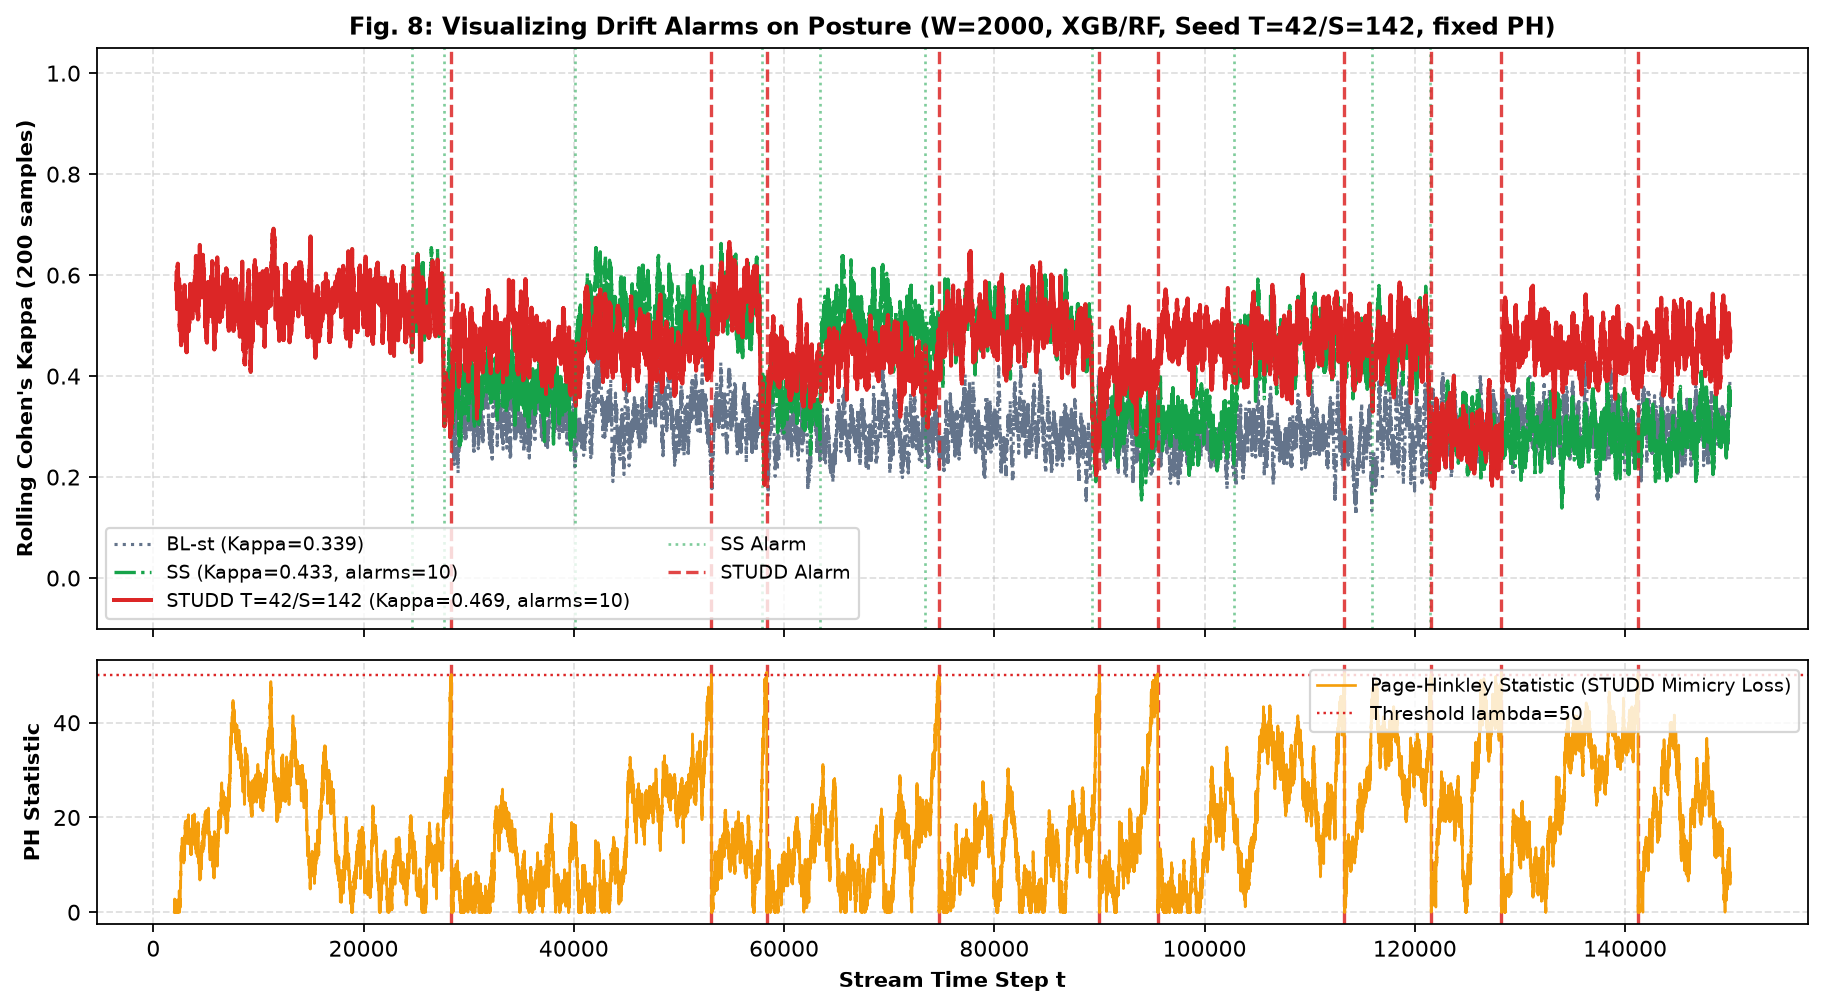

In [5]:
from experiments.extract_full_alarms_and_figs import match_alarms_greedy

df_t5 = pd.read_csv(RESULTS_DIR / "table5_alarm_analysis_19datasets.csv")
print(df_t5[["Method", "SS_Alarmed_Datasets", "Our_MDR", "Paper_MDR", "Our_FAR", "Paper_FAR", "Our_MTD", "Paper_MTD", "Total_Alarms_All19", "F1_Windowed"]].to_string(index=False))
print("\nSanity check greedy alarm matcher (synthetic):", match_alarms_greedy([100, 500], [120, 145, 900], 50))
from IPython.display import Image as _IPyImg, display as _ipy_disp; _ipy_disp(_IPyImg(filename=str(RESULTS_DIR / "fig7_insects_abrupt_alarms.png")))
from IPython.display import Image as _IPyImg, display as _ipy_disp; _ipy_disp(_IPyImg(filename=str(RESULTS_DIR / "fig8_posture_alarms.png")))


## 5. Phân tích Độ nhạy `l_access × l_delay` 2×2 Average Rank (Mục 5.8.5, Hình 14, RQ3)


=== FIG. 14 2x2 AVERAGE RANK BY OBSERVATION PERC. ===
Obs= 1% -> SS:2.63 | STUDD:3.53 | S_W250:4.63 | S_W500:4.74 | S_W1000:4.97 | S_W2000:5.13 | S_W1500:5.16 | S_W4000:5.21
Obs=10% -> SS:2.95 | STUDD:3.95 | S_W250:3.95 | S_W500:4.16 | S_W1000:4.84 | S_W1500:5.26 | S_W2000:5.26 | S_W4000:5.63
Obs=25% -> SS:3.00 | S_W250:3.29 | S_W500:4.24 | STUDD:4.45 | S_W1000:4.61 | S_W2000:5.32 | S_W1500:5.47 | S_W4000:5.63
Obs=50% -> SS:3.05 | S_W250:3.50 | S_W500:4.03 | S_W1000:4.71 | STUDD:4.74 | S_W1500:4.87 | S_W2000:5.45 | S_W4000:5.66

=== SENSITIVITY SUMMARY (MEAN KAPPA & BAYES WIN/ROPE) ===
        Config  Mean_Kappa  Mean_Diff_STUDD_Minus_Cfg  STUDD_Win_Count  STUDD_ROPE_Count  STUDD_Lose_Count  Bayes_P_STUDD_Win_Or_ROPE
         STUDD      0.5166                     0.0000                0                19                 0                        NaN
SS (100%, d=0)      0.5789                    -0.0624                0                 0                 0                        NaN
     

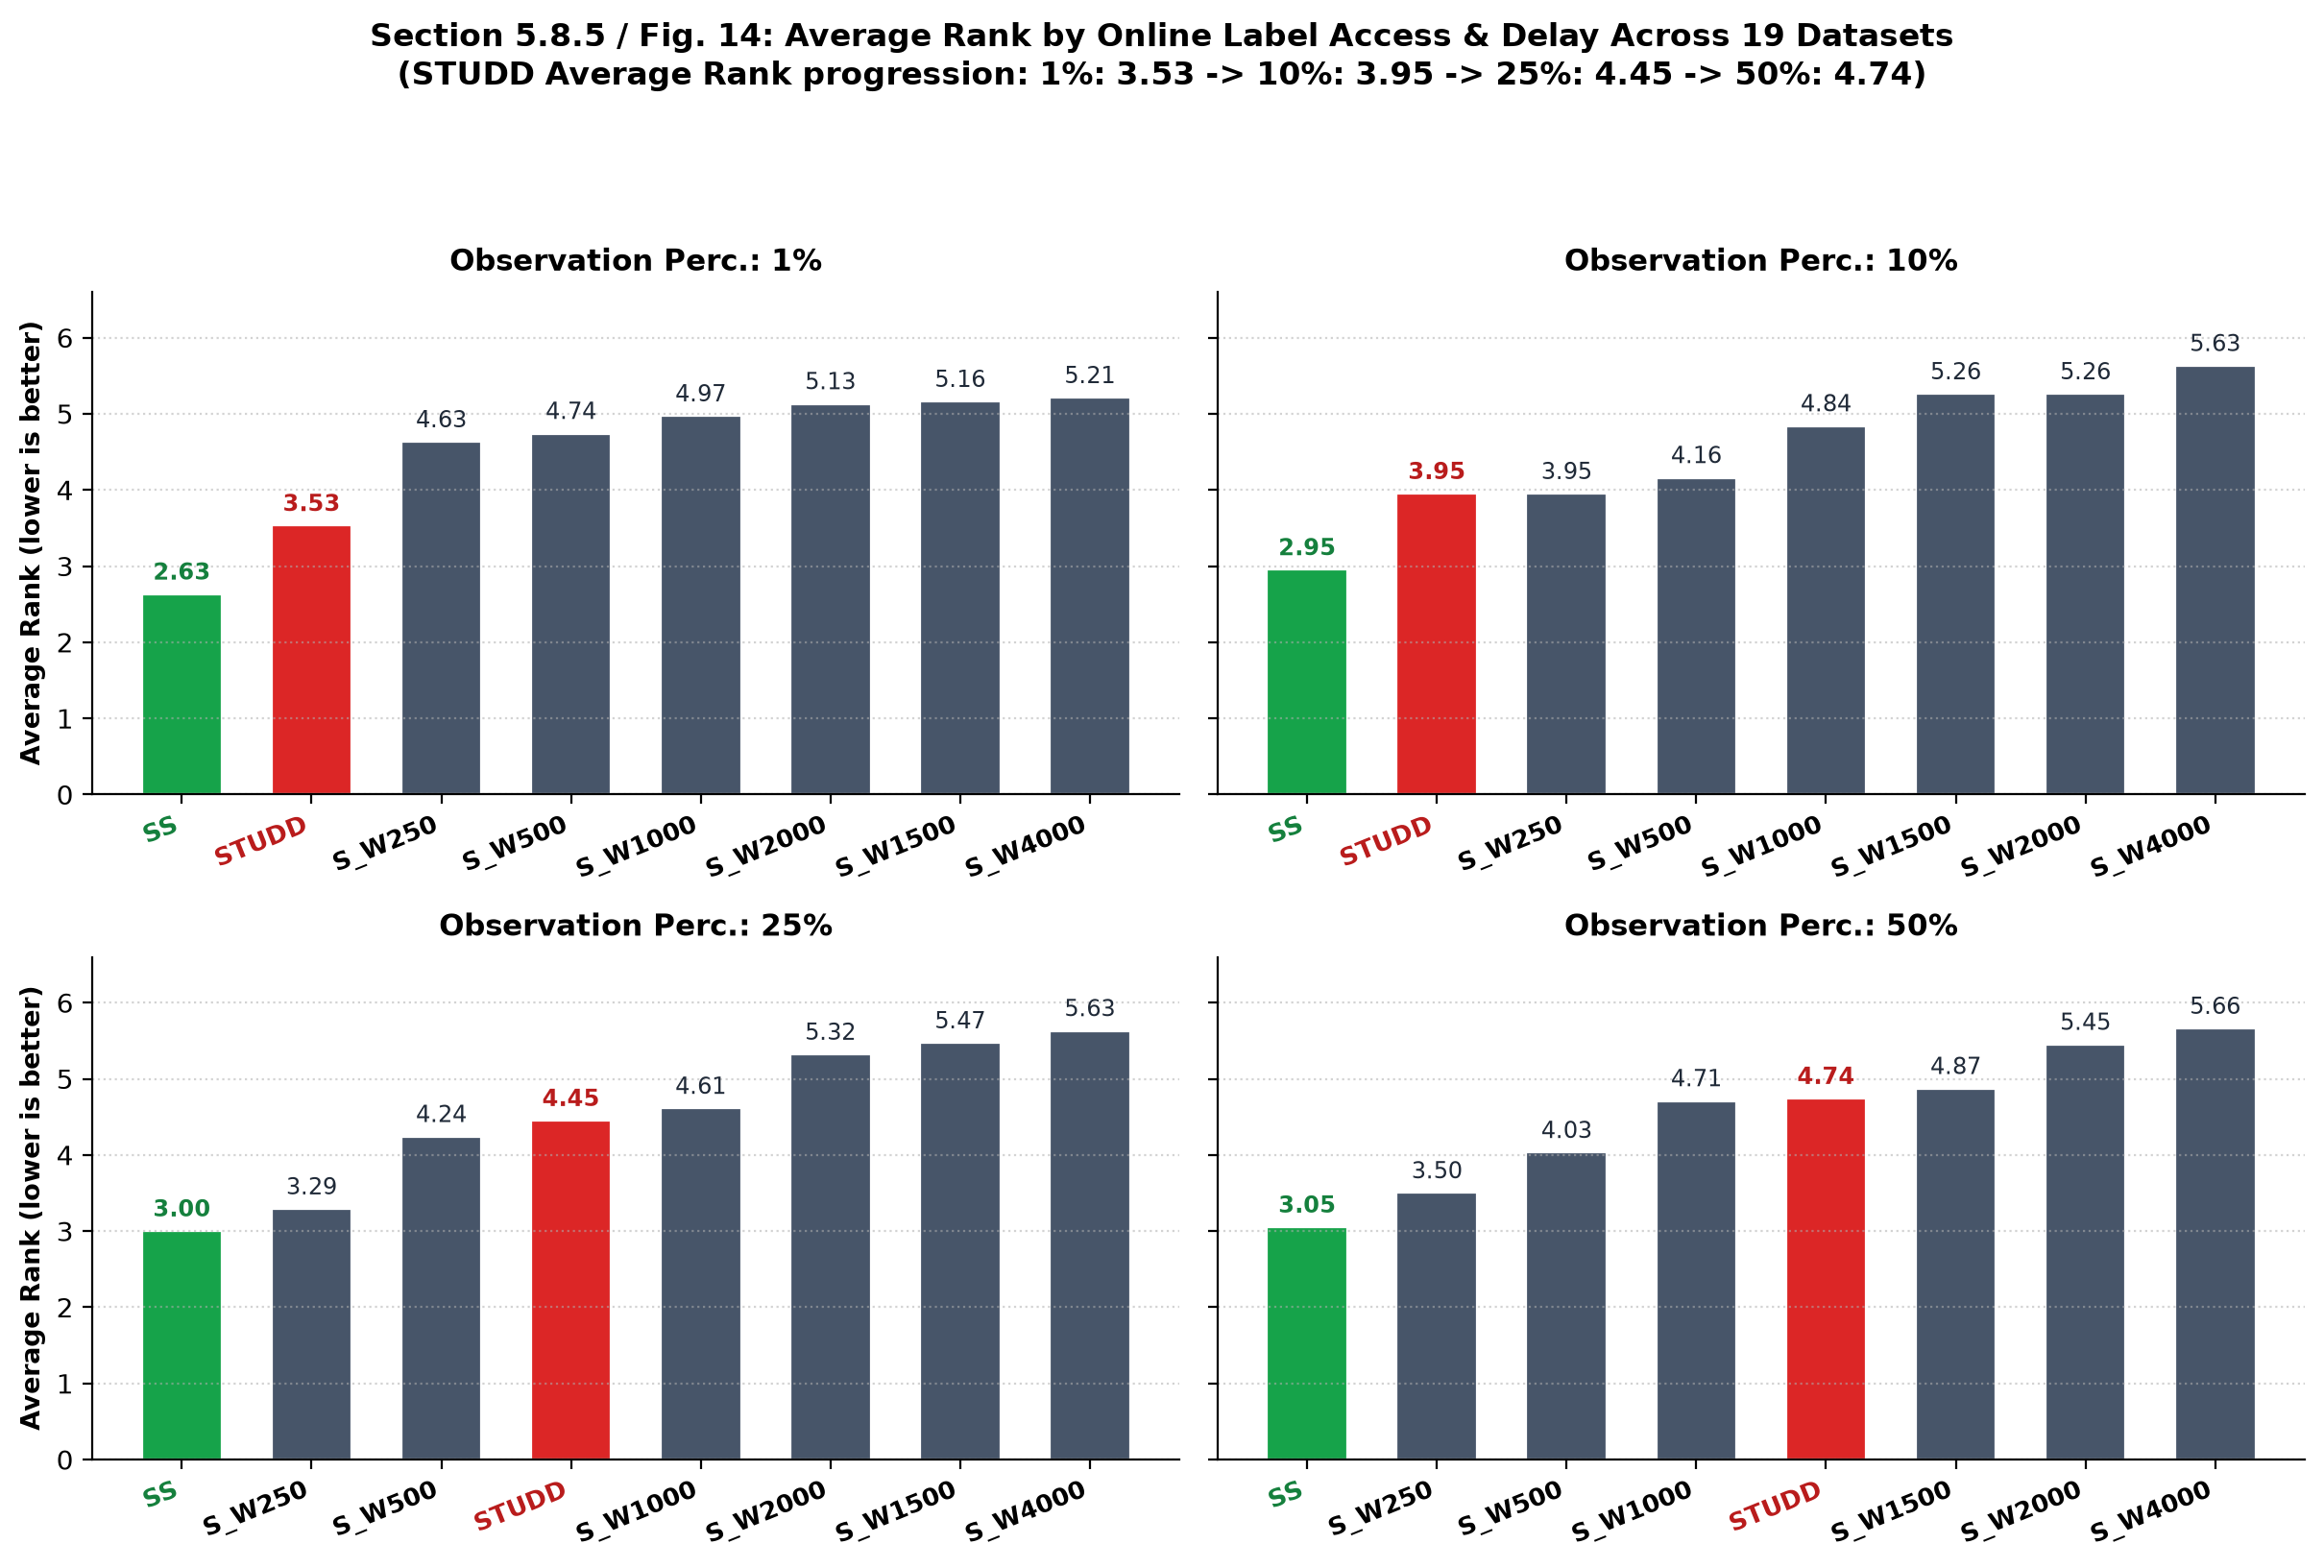

In [6]:
from experiments.run_sensitivity_rq3 import evaluate_delayed_sparse_supervised_pht

df_rq3 = pd.read_csv(RESULTS_DIR / "sensitivity_rq3_summary.csv")
df_ranks = pd.read_csv(RESULTS_DIR / "sensitivity_rq3_ranks_fig14.csv")
print("=== FIG. 14 2x2 AVERAGE RANK BY OBSERVATION PERC. ===")
for pct in (1, 10, 25, 50):
    sub_r = df_ranks[df_ranks["l_access_pct"] == pct].sort_values("Average_Rank")
    print(f"Obs={pct:2d}% -> " + " | ".join(f"{r.Method_Label}:{r.Average_Rank:.2f}" for r in sub_r.itertuples()))
print("\n=== SENSITIVITY SUMMARY (MEAN KAPPA & BAYES WIN/ROPE) ===")
print(df_rq3[["Config", "Mean_Kappa", "Mean_Diff_STUDD_Minus_Cfg", "STUDD_Win_Count", "STUDD_ROPE_Count", "STUDD_Lose_Count", "Bayes_P_STUDD_Win_Or_ROPE"]].to_string(index=False))
from IPython.display import Image as _IPyImg, display as _ipy_disp; _ipy_disp(_IPyImg(filename=str(RESULTS_DIR / "fig14_sensitivity_rq3.png")))


## 6. Đối chiếu Có Kiểm Soát Paper-Text vs Author-Code & Ablation Seed/Detector


=== PROTOCOL A (PAPER-TEXT) VS PROTOCOL B (AUTHOR-CODE AUDIT) ===
      Dataset  W_ProtoA_Text  W_ProtoB_Code  Paper_STUDD_Kappa  ProtoA_STUDD_Kappa  ProtoB_STUDD_Kappa  Paper_STUDD_Cost  ProtoA_STUDD_Cost  ProtoB_STUDD_Cost
    CoverType           2000           1000               0.52              0.4601              0.2469              0.09             0.2933             0.0200
        Poker           2000           1000               0.48              0.2960              0.1932              0.01             0.0133             0.0067
  Powersupply           2000           1000               0.10              0.1036              0.0980              0.07             0.1337             0.0668
  Electricity           2000           1000               0.29              0.4325              0.4009              0.43             0.5738             0.4635
      Sensors           2000           1000               0.59              0.5526              0.3034              0.16             0.9867

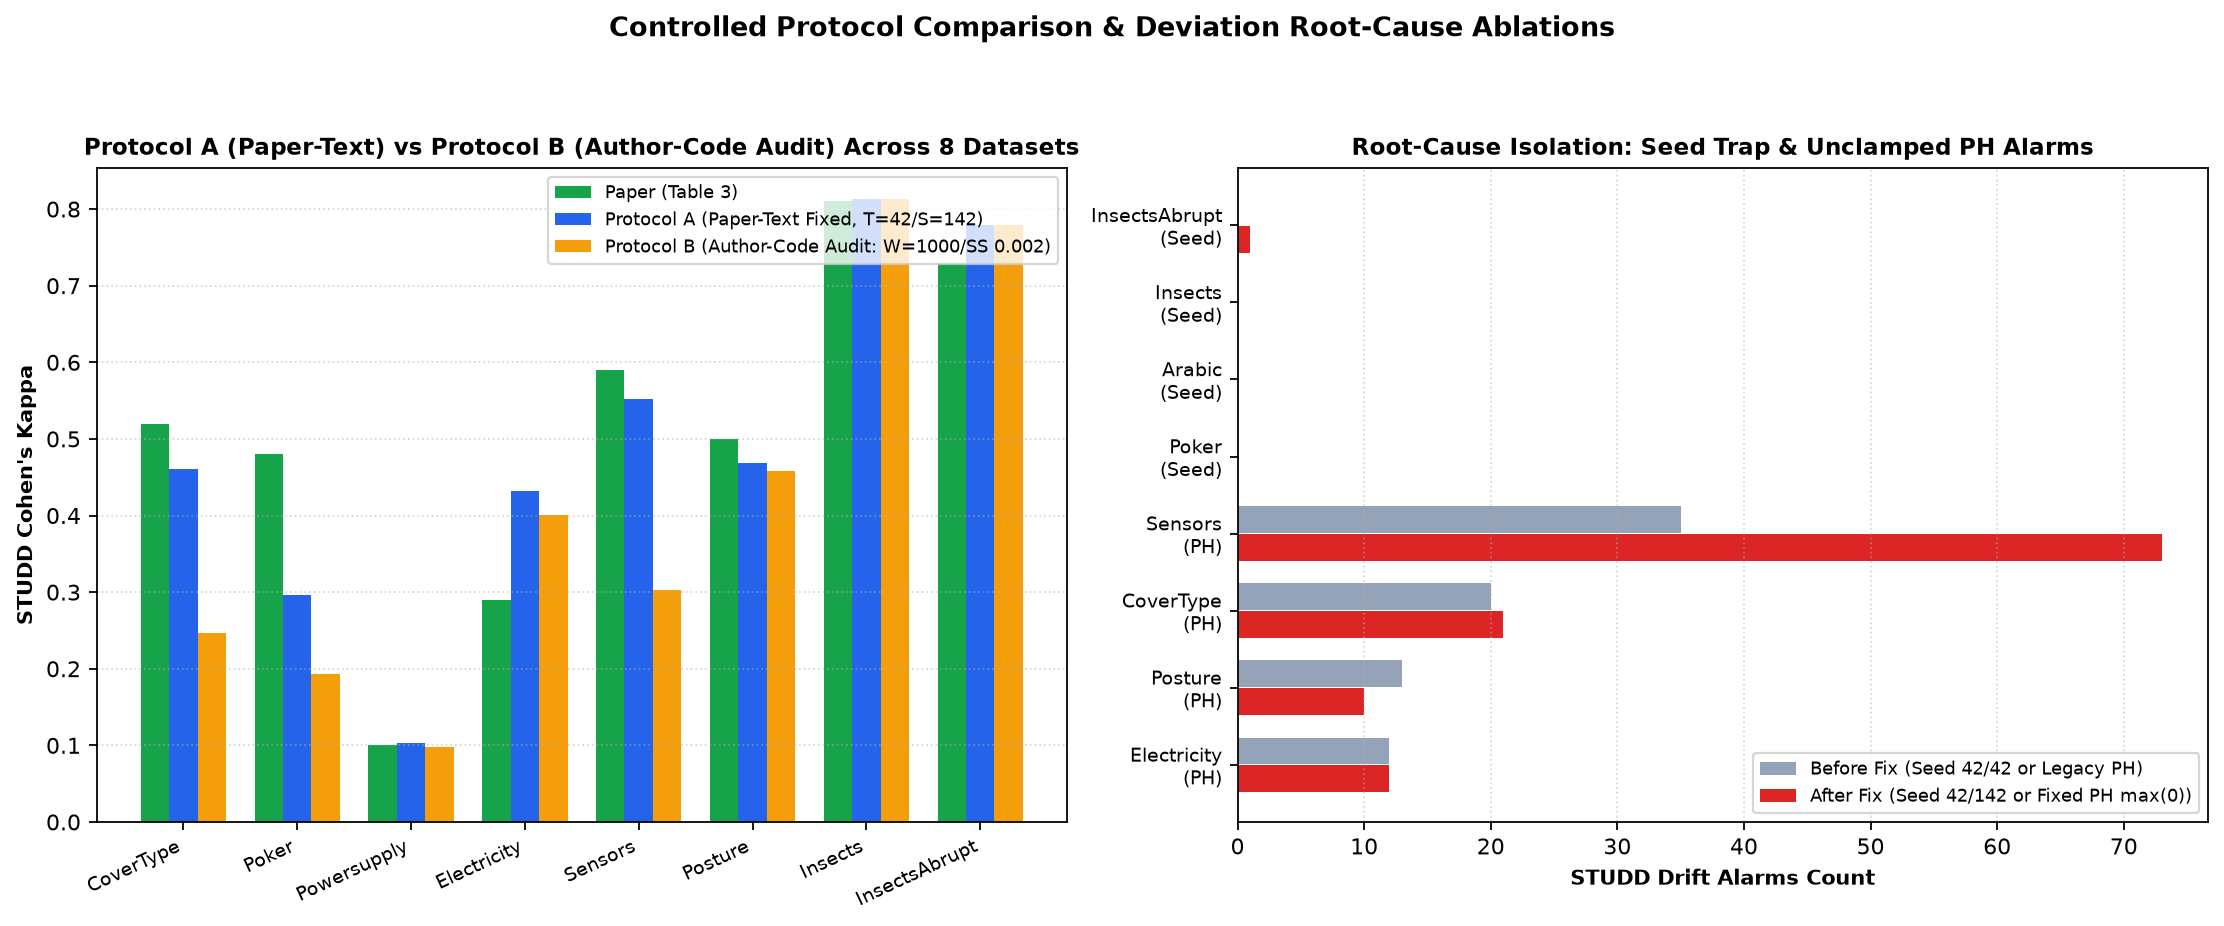

In [7]:
df_proto = pd.read_csv(RESULTS_DIR / "original_code_comparison_table.csv")
df_ab = pd.read_csv(RESULTS_DIR / "seed_and_detector_ablation.csv")

print("=== PROTOCOL A (PAPER-TEXT) VS PROTOCOL B (AUTHOR-CODE AUDIT) ===")
print(df_proto[["Dataset", "W_ProtoA_Text", "W_ProtoB_Code", "Paper_STUDD_Kappa", "ProtoA_STUDD_Kappa", "ProtoB_STUDD_Kappa", "Paper_STUDD_Cost", "ProtoA_STUDD_Cost", "ProtoB_STUDD_Cost"]].to_string(index=False))
print("\n=== SEED & DETECTOR ROOT-CAUSE ABLATIONS ===")
print(df_ab[["Ablation_Type", "Dataset", "Baseline_Alarms", "Treatment_Alarms", "Baseline_Kappa", "Treatment_Kappa", "Baseline_Cost", "Treatment_Cost"]].to_string(index=False))
from IPython.display import Image as _IPyImg, display as _ipy_disp; _ipy_disp(_IPyImg(filename=str(RESULTS_DIR / "fig_protocol_deviation_ablation.png")))
